--- Manual Section Alignment Tool ---

[FATAL ERROR] Could not find a required file: [Errno 2] No such file or directory: 'h:\\My Drive\\Cranfield\\11. Individual Thesis\\Code\\Coordinates\\silverstone_gp_og.csv'
Data loaded. Generating reference map with distance markers...


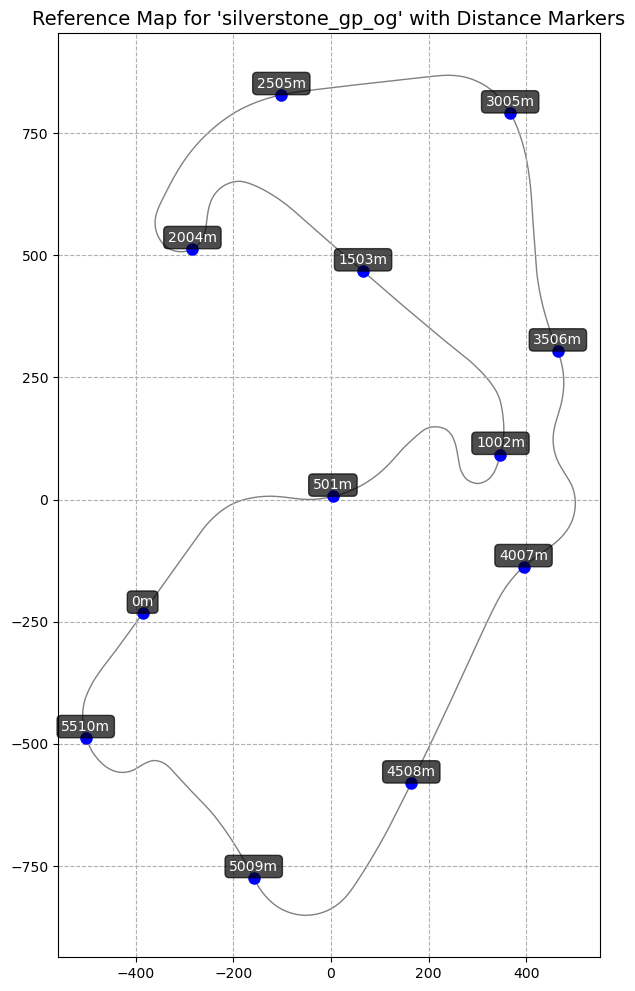


Using an offset of 2615.00 m.

Offset applied and sections have been re-indexed starting from your desired point.

SUCCESS! A new, corrected sections file has been saved to:
h:\My Drive\Cranfield\11. Individual Thesis\Code\Sections\Real\sections_silverstone_gp_og_corrected.csv

Please RENAME this file to its original name to use it in the main script.


: 

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# --- 1. CONFIGURATION ---
# =============================================================================
TRACK_NAME = "silverstone_gp_og"
USE_DUMMY_DATA = False # Using Real data
DISTANCE_MARKER_INTERVAL = 500 

# =============================================================================
# --- 2. HELPER FUNCTION ---
# =============================================================================
def ensure_distance_column(df_coords):
    if 'Distance' in df_coords.columns: return df_coords
    print("   'Distance' column not found. Calculating it now...")
    points = df_coords[['x', 'y', 'z']].to_numpy()
    distances = np.linalg.norm(np.diff(points, axis=0), axis=1)
    cumulative_distance = np.insert(np.cumsum(distances), 0, 0)
    df_coords['Distance'] = cumulative_distance
    return df_coords

# =============================================================================
# --- 3. MAIN MANUAL ALIGNMENT SCRIPT (Final Corrected Version) ---
# =============================================================================

if __name__ == "__main__":
    print("--- Manual Section Alignment Tool ---")
    
    # --- Setup and Load Paths ---
    data_type = "Dummy" if USE_DUMMY_DATA else "Real"
    base_path = os.getcwd()
    coord_path = os.path.join(base_path, "Coordinates", f"{TRACK_NAME}.csv")
    sections_path = os.path.join(base_path, "Sections", data_type, f"sections_{TRACK_NAME}.csv")
    
    try:
        df_coords = pd.read_csv(coord_path)
        df_sections_original = pd.read_csv(sections_path)
    except FileNotFoundError as e:
        print(f"\n[FATAL ERROR] Could not find a required file: {e}")
        exit()

    df_coords = ensure_distance_column(df_coords)
    print("Data loaded. Generating reference map with distance markers...")

    # --- Step 1: Generate Reference Plot (Unchanged) ---
    fig, ax = plt.subplots(figsize=(12, 12))
    ax.plot(df_coords['x'], df_coords['y'], color='grey', zorder=1, linewidth=1)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f"Reference Map for '{TRACK_NAME}' with Distance Markers", fontsize=14)
    ax.grid(True, linestyle='--')
    last_marker_dist = -DISTANCE_MARKER_INTERVAL
    for i, row in df_coords.iterrows():
        dist = row['Distance']
        if dist >= last_marker_dist + DISTANCE_MARKER_INTERVAL:
            ax.plot(row['x'], row['y'], 'o', color='blue', markersize=8)
            ax.text(row['x'], row['y'] + 15, f"{dist:.0f}m", color='white', ha='center',
                    bbox=dict(facecolor='black', alpha=0.7, pad=2, boxstyle='round,pad=0.3'))
            last_marker_dist = dist
    plt.show()

    # --- Step 2: Prompt User for Offset (Unchanged) ---
    distance_offset = None
    while distance_offset is None:
        try:
            prompt_message = "\nExamine the plot above. Estimate the distance (m) of the true telemetry start point and enter it here: "
            user_input = input(prompt_message)
            distance_offset = float(user_input)
        except ValueError:
            print("[Error] Invalid input. Please enter a number.")

    # --- Step 3: Apply Offset and Re-order Sections ---
    total_track_length = df_coords['Distance'].max()
    print(f"\nUsing an offset of {distance_offset:.2f} m.")
    
    df_sections_corrected = df_sections_original.copy()
    
    df_sections_corrected['start_m'] = pd.to_numeric(df_sections_corrected['start_m'], errors='coerce')
    df_sections_corrected['end_m'] = pd.to_numeric(df_sections_corrected['end_m'], errors='coerce')
    df_sections_corrected.dropna(subset=['start_m', 'end_m'], inplace=True)

    df_sections_corrected['start_m'] = (df_sections_corrected['start_m'] + distance_offset) % total_track_length
    df_sections_corrected['end_m'] = (df_sections_corrected['end_m'] + distance_offset) % total_track_length

    # --- CORRECTED LOGIC TO FIND THE TRUE STARTING SECTION ---
    # Instead of finding the minimum distance, find the section start closest to the offset you entered.
    # This correctly identifies your desired starting point.
    new_start_index = (df_sections_corrected['start_m'] - distance_offset).abs().idxmin()
    # --- END OF CORRECTION ---
    
    # "Roll" the DataFrame so that the new start section is at the top.
    df_reordered = pd.concat([
        df_sections_corrected.loc[new_start_index:],
        df_sections_corrected.loc[:new_start_index-1]
    ])
    
    # Re-assign the segment_id to be sequential from 0.
    df_reordered['segment_id'] = range(len(df_reordered))
    

    print("\nOffset applied and sections have been re-indexed starting from your desired point.")

    # --- Save the Corrected File ---
    output_filename = f"sections_{TRACK_NAME}_corrected.csv"
    output_path = os.path.join(base_path, "Sections", data_type, output_filename)
    
    df_reordered.to_csv(output_path, index=False, float_format='%.4f')
    
    print(f"\nSUCCESS! A new, corrected sections file has been saved to:")
    print(output_path)
    print("\nPlease RENAME this file to its original name to use it in the main script.")